# Building Agents That Use Code

This notebook is part of the [Hugging Face Agents Course](https://www.hf.co/learn/agents-course), a free Course from beginner to expert, where you learn to build Agents.

![Agents course share](https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/communication/share.png)

> **Validation status.** Preserved outputs are historical evidence from the supplied notebook. Local checks may add their own evidence. Consult the accompanying validation report for the checks run on this revision and the exercises still pending authenticated Colab verification.

## Let's install the dependencies and configure our inference provider

If you haven't installed `smolagents` yet, you can do so by running the following command. This Colab adaptation uses Groq for the agent model, rather than the Hugging Face Inference API.

In [1]:
%pip install -q "smolagents[openai,toolkit]==1.26.0" "requests==2.32.4" ddgs beautifulsoup4 "gradio_client==2.7.2" langchain-core pillow


Enable `GROQ_API_KEY` in Colab Secrets (key icon). No Hugging Face sign-in is required for Groq inference. The Hub publication and the Hub Inference API image exercise have separate opt-in switches and may require a Hugging Face token and quota. The public Space image exercise is opt-in in this fast configuration; enable RUN_SPACE_IMAGE in the setup cell if you want to attempt it. SerpAPI is optional; the default search uses DDGS with automatic backend selection.

Groq native tool calling is enabled. A genuine text answer can be adapted locally into smolagents' final-answer format. Each required tool is checked in the execution trace. Hub publication and token-backed image generation remain opt-in. The public Space is enabled. The search fallback reads public source pages when the search services cannot return usable links.


In [ ]:
import os
from time import monotonic, sleep
from uuid import uuid4

from openai import APIConnectionError, APIStatusError, OpenAI, RateLimitError
from smolagents import OpenAIModel, ToolCallingAgent
from smolagents.models import ChatMessageToolCall, ChatMessageToolCallFunction

def read_secret(name):
    value = os.getenv(name)
    if value:
        return value
    try:
        from google.colab import userdata
    except ImportError:
        return None
    try:
        return userdata.get(name)
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        return None

GROQ_API_KEY = read_secret("GROQ_API_KEY")
GROQ_BASE = "https://api.groq.com/openai/v1"
client = (OpenAI(api_key=GROQ_API_KEY, base_url=GROQ_BASE, timeout=20, max_retries=0)
          if GROQ_API_KEY else None)
MODEL_ID = os.getenv("GROQ_MODEL_ID", "openai/gpt-oss-120b")
VISION_MODEL_ID = os.getenv("GROQ_VISION_MODEL_ID", "qwen/qwen3.8-27b")
TEXT_MODELS = (MODEL_ID, "openai/gpt-oss-20b", "qwen/qwen3.8-27b")
MODEL_REQUEST_LIMIT = int(os.getenv("GROQ_MAX_REQUESTS", "24"))
model_requests = 0
last_model_request = 0.0

class GroqAgentModel(OpenAIModel):
    """Use Groq's native tool validation and accept genuine text final answers."""
    def _prepare_completion_kwargs(self, *args, **kwargs):
        policy = getattr(self, "tool_policy", None)
        forced = policy() if policy and kwargs.get("tools_to_call_from") else None
        kwargs["tool_choice"] = (
            {"type": "function", "function": {"name": forced}} if forced else "auto"
        )
        request = super()._prepare_completion_kwargs(*args, **kwargs)
        request.pop("stop", None)
        for message in request["messages"]:
            message.pop("name", None)
        if request.get("tools"):
            request["parallel_tool_calls"] = False
        # Keep tool calls and their observations together; do not truncate message history.
        request.setdefault("max_completion_tokens", 2000)
        return request

    def generate(self, messages, *args, tools_to_call_from=None, **kwargs):
        global model_requests, last_model_request
        original_model = self.model_id
        original_options = self.kwargs.copy()
        options = (original_model,) if original_model == VISION_MODEL_ID else TEXT_MODELS
        deadline = monotonic() + 150
        try:
            for attempt in range(2):
                if model_requests >= MODEL_REQUEST_LIMIT or monotonic() >= deadline:
                    raise RuntimeError("Model request budget exhausted.")
                self.model_id = options[min(attempt, len(options) - 1)]
                self.kwargs.pop("reasoning_effort", None)
                if self.model_id.startswith("openai/gpt-oss"):
                    self.kwargs["reasoning_effort"] = "low"
                elif self.model_id == VISION_MODEL_ID:
                    self.kwargs["reasoning_effort"] = "none"
                sleep(max(0, 45 - (monotonic() - last_model_request)))
                last_model_request = monotonic()
                model_requests += 1
                try:
                    reply = super().generate(
                        messages, *args, tools_to_call_from=tools_to_call_from, **kwargs
                    )
                except (APIStatusError, APIConnectionError) as exc:
                    status = getattr(exc, "status_code", 0) or 0
                    code = getattr(exc, "code", None)
                    recoverable = (status in (404, 429) or status >= 500 or status == 0
                                   or code in ("tool_use_failed", "model_decommissioned"))
                    if attempt or not recoverable:
                        raise RuntimeError(
                            f"Groq request failed for {self.model_id} (HTTP {status or 'connection'}, "
                            f"{code or type(exc).__name__})."
                        ) from None
                    if isinstance(exc, RateLimitError):
                        try:
                            delay = float(exc.response.headers.get("retry-after", "2"))
                        except ValueError:
                            delay = 2
                        if delay > 60:
                            raise RuntimeError(
                                f"Groq vision quota is limited; retry after {delay:g} seconds."
                            ) from None
                        sleep(max(1, min(delay, 60)))
                    print("Groq request interrupted; making one bounded retry.")
                    continue
                names = {tool.name for tool in tools_to_call_from or ()}
                text = reply.content
                if ("final_answer" in names and not reply.tool_calls
                        and isinstance(text, str) and text.strip()):
                    # smolagents expects a final_answer action. Carry the real text into
                    # that action locally without changing any external tool observations.
                    # Normalize only an explicit final-answer envelope, never arbitrary tool calls.
                    import json
                    try:
                        envelope = json.loads(text.strip())
                        if isinstance(envelope, dict) and envelope.get("name") == "final_answer":
                            answer = envelope.get("arguments", {}).get("answer")
                            if isinstance(answer, str):
                                text = answer
                    except (ValueError, TypeError):
                        pass
                    reply.tool_calls = [ChatMessageToolCall(
                        function=ChatMessageToolCallFunction(
                            name="final_answer", arguments={"answer": text.strip()}),
                        id=f"local_final_{uuid4().hex}", type="function",
                    )]
                if attempt:
                    print("Groq retry completed with", self.model_id)
                return reply
        finally:
            self.model_id = original_model
            self.kwargs = original_options

def make_model(max_tokens=2000, model_id=MODEL_ID):
    if not client:
        raise RuntimeError("Enable notebook access to GROQ_API_KEY in Colab Secrets.")
    return GroqAgentModel(
        model_id=model_id, api_base=GROQ_BASE, api_key=GROQ_API_KEY,
        temperature=0.2, max_completion_tokens=max_tokens, retry=False,
        client_kwargs={"timeout": 20, "max_retries": 0},
    )

def completed_tools(agent):
    return {
        call.name for step in agent.memory.steps
        if getattr(step, "error", None) is None
        for call in (getattr(step, "tool_calls", None) or ())
    }

def run_checked(agent, prompt, required=(), ordered=(), **kwargs):
    global model_requests
    if agent.model is None:
        raise RuntimeError("Configure GROQ_API_KEY in environment variables or Colab Secrets before agent inference.")
    # Each top-level exercise has its own budget, shared with its managed agents.
    model_requests = 0
    def next_tool():
        completed = completed_tools(agent)
        return next((name for name in ordered if name not in completed), None)

    agent.model.tool_policy = next_tool
    try:
        result = agent.run(prompt, return_full_result=True, **kwargs)
    finally:
        agent.model.tool_policy = None
    missing = set(required) - completed_tools(agent)
    if result.state != "success" or missing or not result.output:
        raise RuntimeError(f"Agent exercise incomplete: {result.state}; missing tools: {sorted(missing)}.")
    if result.token_usage:
        print("Agent tokens:", result.token_usage)
    return result.output

# Keep local tool checks available even when Groq credentials are unavailable.
model = make_model() if client else None

PUBLISH_TO_HUB = False
RUN_HUB_IMAGE = False  # Opt in only after checking HF inference quota and cost.
RUN_SPACE_IMAGE = True  # Public FLUX Space; availability can depend on quota.
USE_SERPAPI = False  # Optional, may depend on your SerpAPI quota.
HF_REPO_ID = "angiedonatto/superhero_party_theme_generator"

optional_secret = read_secret

from IPython.display import display
from pathlib import Path
from PIL import Image as PILImage

def show_generated_image(value):
    """Display a real image returned by an agent/tool, without a fixed temporary path."""
    if isinstance(value, (list, tuple)):
        return any([show_generated_image(item) for item in value])
    if isinstance(value, dict):
        value = value.get("path", value.get("image", value.get("value")))
    if hasattr(value, "to_raw"):
        value = value.to_raw()
    if isinstance(value, PILImage.Image):
        display(value)
        return True
    if isinstance(value, (str, Path)):
        try:
            with PILImage.open(value) as image:
                display(image.copy())
            return True
        except (OSError, ValueError):
            return False
    return False


## The `@tool` Decorator  

### Generating a tool that retrieves the highest-rated catering

Let's imagine that Alfred has already decided on the menu for the party, but now he needs help preparing food for such a large number of guests. To do so, he would like to hire a catering service and needs to identify the highest-rated options available. Alfred can leverage a tool to search for the best catering services in his area.

Below is an example of how Alfred can use the `@tool` decorator to make this happen:

In [4]:
from smolagents import ToolCallingAgent, tool

# Let's pretend we have a function that fetches the highest-rated catering services.
@tool
def catering_service_tool(query: str) -> str:
    """
    This tool returns the highest-rated catering service in Gotham City.

    Args:
        query: A search term for finding catering services.
    """
    # Example list of catering services and their ratings
    services = {
        "Gotham Catering Co.": 4.9,
        "Wayne Manor Catering": 4.8,
        "Gotham City Events": 4.7,
    }

    # Find the highest rated catering service (simulating search query filtering)
    best_service = max(services, key=services.get)

    return best_service


print("Direct tool check:", catering_service_tool("highest-rated catering"))

agent = ToolCallingAgent(tools=[catering_service_tool], model=model, max_steps=4)

# Run the agent to find the best catering service
result = run_checked(
    agent,
    "Can you give me the name of the highest-rated catering service in Gotham City? Use catering_service_tool before answering.",
    required=("catering_service_tool",), ordered=("catering_service_tool",),
)

print(result)


Direct tool check: Gotham Catering Co.


╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Can you give me the name of the highest-rated catering service in Gotham City? Use catering_service_tool before │
│ answering.                                                                                                      │
│                                                                                                                 │
╰─ GroqAgentModel - openai/gpt-oss-20b ───────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'catering_service_tool' with arguments: {'query': 'Gotham City catering'}                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: Gotham Catering Co.

[Step 1: Duration 2.14 seconds| Input tokens: 1,027 | Output tokens: 46]

... (2 outputs left out)

Observations: Gotham Catering Co.

Final answer: Gotham Catering Co.

[Step 2: Duration 0.58 seconds| Input tokens: 2,141 | Output tokens: 79]

Agent tokens: TokenUsage(input_tokens=2141, output_tokens=79, total_tokens=2220)
Gotham Catering Co.


## Defining a Tool as a Python Class  

### Generating a tool to generate ideas about the superhero-themed party

Alfred's party at the mansion is a **superhero-themed event**, but he needs some creative ideas to make it truly special. As a fantastic host, he wants to surprise the guests with a unique theme.

To do this, he can use an agent that generates superhero-themed party ideas based on a given category. This way, Alfred can find the perfect party theme to wow his guests.

In [5]:
from smolagents import Tool, ToolCallingAgent

class SuperheroPartyThemeTool(Tool):
    name = "superhero_party_theme_generator"
    description = """
    This tool suggests creative superhero-themed party ideas based on a category.
    It returns a unique party theme idea."""

    inputs = {
        "category": {
            "type": "string",
            "description": "The type of superhero party (e.g., 'classic heroes', 'villain masquerade', 'futuristic Gotham').",
        }
    }

    output_type = "string"

    def forward(self, category: str):
        themes = {
            "classic heroes": "Justice League Gala: Guests come dressed as their favorite DC heroes with themed cocktails like 'The Kryptonite Punch'.",
            "villain masquerade": "Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.",
            "futuristic gotham": "Neo-Gotham Night: A cyberpunk-style party inspired by Batman Beyond, with neon decorations and futuristic gadgets."
        }

        return themes.get(category.lower(), "Themed party idea not found. Try 'classic heroes', 'villain masquerade', or 'futuristic Gotham'.")

# Instantiate the tool
party_theme_tool = SuperheroPartyThemeTool()
print("Direct tool check:", party_theme_tool("villain masquerade"))

agent = ToolCallingAgent(tools=[party_theme_tool], model=model, max_steps=4)

# Run the agent to generate a party theme idea
result = run_checked(
    agent,
    "What would be a good superhero party idea for a 'villain masquerade' theme? Use superhero_party_theme_generator before answering.",
    required=("superhero_party_theme_generator",), ordered=("superhero_party_theme_generator",),
)

print(result)


Direct tool check: Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.


╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ What would be a good superhero party idea for a 'villain masquerade' theme? Use superhero_party_theme_generator │
│ before answering.                                                                                               │
│                                                                                                                 │
╰─ GroqAgentModel - openai/gpt-oss-20b ───────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'superhero_party_theme_generator' with arguments: {'category': 'villain masquerade'}              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains.

[Step 1: Duration 0.30 seconds| Input tokens: 1,092 | Output tokens: 49]

... (2 outputs left out)

Observations: {
  "name": "final_answer",
  "arguments": {
    "answer": "Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains."
  }
}

Final answer: {
  "name": "final_answer",
  "arguments": {
    "answer": "Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains."
  }
}

[Step 2: Duration 0.51 seconds| Input tokens: 2,280 | Output tokens: 105]

Agent tokens: TokenUsage(input_tokens=2280, output_tokens=105, total_tokens=2385)
{
  "name": "final_answer",
  "arguments": {
    "answer": "Gotham Rogues' Ball: A mysterious masquerade where guests dress as classic Batman villains."
  }
}


## Sharing a Tool to the Hub

Sharing your custom tool with the community is easy! Simply upload it to your Hugging Face account using the `push_to_hub()` method.

For instance, Alfred can share his `catering_service_tool` to help others find the best catering services in Gotham. Here's how to do it:

**Colab adaptation:** The original code publishes the party theme tool, so the repository name below matches that tool. A local export is attempted first; actual Hub publication is optional and requires a write-enabled `HF_TOKEN`. A local export is not a published Space.

In [6]:
from pathlib import Path

export_dir = Path("superhero_party_theme_tool")
try:
    party_theme_tool.save(export_dir)
    print("Local tool export:", export_dir)
except Exception as exc:
    print("Local tool export not completed:", type(exc).__name__, str(exc))

if PUBLISH_TO_HUB:
    hf_token = optional_secret("HF_TOKEN")
    if hf_token:
        try:
            party_theme_tool.push_to_hub(HF_REPO_ID, token=hf_token, private=True)
            print("Published:", f"https://huggingface.co/spaces/{HF_REPO_ID}")
        except Exception as exc:
            print("Hub publication not completed:", type(exc).__name__)
    else:
        print("Hub publication skipped: HF_TOKEN is missing.")
else:
    print("Hub publication not requested.")

Local tool export: superhero_party_theme_tool
Hub publication not requested.


## Importing a Tool from the Hub

You can easily import tools created by other users using the `load_tool()` function. For example, Alfred might want to generate a promotional image for the party using AI. Instead of building a tool from scratch, he can leverage a predefined one from the community:

**Colab adaptation:** This particular shared tool calls the Hugging Face Inference API for text-to-image generation; Groq only controls the agent. Before enabling `RUN_HUB_IMAGE`, review the [remote tool code](https://huggingface.co/spaces/m-ric/text-to-image/blob/main/tool.py) and check your HF inference quota. No API calls to this image provider are made by default.

In [7]:
from smolagents import load_tool
from huggingface_hub import InferenceClient

hub_image_result = None
if RUN_HUB_IMAGE:
    hf_token = optional_secret("HF_TOKEN")
    if not hf_token:
        raise RuntimeError("Enable HF_TOKEN with Inference Providers access for this exercise.")
    image_generation_tool = load_tool(
        "m-ric/text-to-image", token=hf_token, trust_remote_code=True
    )
    image_generation_tool.client = InferenceClient(
        model="black-forest-labs/FLUX.1-schnell", token=hf_token, timeout=45,
    )
    agent = ToolCallingAgent(tools=[image_generation_tool], model=make_model(), max_steps=3)
    hub_image_result = run_checked(
        agent, "Generate a promotional image of a luxurious superhero party at Wayne Manor and return image.png from agent memory.",
        required=(image_generation_tool.name,), ordered=(image_generation_tool.name,),
    )
    if not show_generated_image(hub_image_result):
        raise RuntimeError("The Hub tool did not return a displayable image.")
else:
    print("Hub Inference API image exercise is disabled; see the setup flags.")


Hub Inference API image exercise is disabled; see the setup flags.


## Importing a Hugging Face Space as a Tool

You can also import a HF Space as a tool using `Tool.from_space()`. This opens up possibilities for integrating with thousands of spaces from the community for tasks from image generation to data analysis.

The tool will connect with the spaces Gradio backend using the `gradio_client`, so make sure to install it via `pip` if you don't have it already. For the party, Alfred can also use a HF Space directly for the generation of the previous annoucement AI-generated image. Let's build it!

**Colab adaptation:** Calls the original public FLUX.1-schnell Space. Public availability, GPU quotas and the remote API may change. The agent still uses the Groq model. If the service fails, the notebook reports that fact rather than substituting an unrelated image.

In [3]:
# gradio_client was installed in the first cell.
import gradio_client
print("Gradio client available:", gradio_client.__version__)

Gradio client available: 2.7.2


In [ ]:
from smolagents import Tool

space_image_result = None
if RUN_SPACE_IMAGE:
    image_model = make_model(max_tokens=1400)
    # smolagents 1.26 uses the old hf_token keyword; adapt it to Gradio 2.x.
    from gradio_client import Client as CurrentClient
    import gradio_client
    def compatible_client(*args, hf_token=None, **kwargs):
        kwargs.setdefault("httpx_kwargs", {"timeout": 15})
        return CurrentClient(*args, token=hf_token, **kwargs)
    gradio_client.Client = compatible_client
    try:
        image_generation_tool = Tool.from_space(
        "black-forest-labs/FLUX.1-schnell", name="image_generator",
        description="Generate an image from a text prompt", api_name="/infer",
    )

    finally:
        gradio_client.Client = CurrentClient

    def generate_space_image(prompt, **kwargs):
        kwargs.update(width=512, height=512, num_inference_steps=4)
        job = image_generation_tool.client.submit(
            prompt=prompt, api_name="/infer", **kwargs,
        )
        try:
            output = job.result(timeout=45)
        except TimeoutError:
            job.cancel()
            raise
        return output[0] if isinstance(output, (tuple, list)) else output

    image_generation_tool.forward = generate_space_image
    agent = ToolCallingAgent(tools=[image_generation_tool], model=image_model, max_steps=3)
    space_image_result = run_checked(
        agent, "Improve the prompt, generate a promotional image of a luxurious superhero gala at Wayne Manor, "
        "and return the resulting image.png from agent memory.",
        required=("image_generator",), ordered=("image_generator",),
    )
else:
    print("Public Space image exercise is disabled; see the setup flags.")

# Resolve a genuine image reference returned by the model from agent memory.
if isinstance(space_image_result, str):
    import json
    try:
        payload=json.loads(space_image_result)
        if isinstance(payload,dict) and payload.get('name')=='final_answer':
            space_image_result=payload.get('arguments',{}).get('answer',space_image_result)
    except ValueError:
        pass
    if space_image_result in agent.state:
        space_image_result=agent.state[space_image_result]


In [ ]:
if RUN_SPACE_IMAGE and space_image_result is not None:
    if not show_generated_image(space_image_result):
        raise RuntimeError("The Space did not return a displayable image.")
else:
    print("No generated image to display. Configure the provider and run the image exercise first.")


## Importing a LangChain Tool

These tools need a [SerpApi API Key](https://serpapi.com/).

You can easily load LangChain tools using the `Tool.from_langchain()` method. Alfred, ever the perfectionist, is preparing for a spectacular superhero night at Wayne Manor while the Waynes are away. To make sure every detail exceeds expectations, he taps into LangChain tools to find top-tier entertainment ideas.

By using `Tool.from_langchain()`, Alfred effortlessly adds advanced search functionalities to his smolagent, enabling him to discover exclusive party ideas and services with just a few commands.

Here's how he does it:

**Colab adaptation:** SerpAPI is optional. The default uses a LangChain `StructuredTool` wrapping the same free DDGS automatic backend used in the earlier Code Agents notebook. In both cases, `Tool.from_langchain()` performs the integration.

In [10]:
# The dependencies for both search backends were installed above.
from langchain_core.tools import StructuredTool
from ddgs import DDGS
from smolagents import ToolCallingAgent, Tool

In [11]:
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache
from urllib.parse import urlparse
from xml.etree import ElementTree

import requests
from bs4 import BeautifulSoup
from ddgs import DDGS

PARTY_SOURCES = (
    "https://www.obrienproductions.com/theme-parties/superhero/",
    "https://www.hipentertainment.com/works/super-heroes",
    "https://www.bizbash.com/event-decor/15-ideas-for-superhero-themed-events",
)
HEADERS = {"User-Agent": "HF-Agents-Course-Colab/1.0 (educational notebook; public sources only)"}

@lru_cache(maxsize=24)
def search_hits(query, fallback_urls=()):
    try:
        hits = DDGS(timeout=8).text(query, max_results=4, backend="auto")
        hits = [hit for hit in hits if urlparse(hit.get("href", "")).scheme == "https"]
        if hits:
            return "DDGS", hits
    except Exception:
        pass

    try:
        response = requests.get(
            "https://www.bing.com/search", params={"q": query, "format": "rss"},
            headers=HEADERS, timeout=(4, 7),
        )
        response.raise_for_status()
        feed = ElementTree.fromstring(response.content)
        hits = [
            {"title": item.findtext("title", ""), "href": item.findtext("link", ""),
             "body": item.findtext("description", "")}
            for item in feed.findall("./channel/item")[:4]
            if item.findtext("link", "").startswith("https://")
        ]
        if hits:
            return "Bing RSS", hits
    except (requests.RequestException, ElementTree.ParseError):
        pass

    def read_source(url):
        try:
            response = requests.get(url, headers=HEADERS, timeout=(4, 7))
            response.raise_for_status()
            soup = BeautifulSoup(response.content, "html.parser")
            title = soup.title.get_text(" ", strip=True) if soup.title else ""
            if not title:
                return None
            meta = soup.find("meta", attrs={"name": "description"})
            summary = meta.get("content", "") if meta else ""
            if not summary:
                summary = " ".join(p.get_text(" ", strip=True) for p in soup.select("main p, article p")[:5])
            return {"title": title, "href": response.url, "body": summary[:400]}
        except requests.RequestException:
            return None

    if fallback_urls:
        with ThreadPoolExecutor(max_workers=3) as workers:
            hits = [hit for hit in workers.map(read_source, fallback_urls) if hit]
        if hits:
            return "live reads of curated public sources", hits
    return "unavailable", []

def format_hits(backend, hits):
    entries = [
        f"{hit['title']} | {hit['href']} | {hit['body'][:350]}"
        for hit in hits
    ]
    if not entries:
        return "No sources retrieved. Report this limitation."
    return f"Retrieval: {backend}\n" + "\n".join(entries)

def search_entertainment(query: str) -> str:
    """Search for entertainment ideas and return real titles, URLs and snippets."""
    backend, hits = search_hits(query, PARTY_SOURCES)
    retrieved_urls.update(hit["href"] for hit in hits)
    return format_hits(backend, hits)

retrieved_urls = set()

serpapi_key = optional_secret("SERPAPI_API_KEY") if USE_SERPAPI else None
if serpapi_key:
    def search_serpapi(query: str) -> str:
        """Retrieve public entertainment sources with SerpAPI."""
        try:
            reply = requests.get(
                "https://serpapi.com/search.json",
                params={"q": query, "api_key": serpapi_key, "engine": "google"},
                timeout=(4, 8),
            )
            reply.raise_for_status()
            hits = [
                {"title": item.get("title", ""), "href": item["link"],
                 "body": item.get("snippet", "")}
                for item in reply.json().get("organic_results", [])[:4]
                if item.get("link", "").startswith("https://")
            ]
            if hits:
                retrieved_urls.update(hit["href"] for hit in hits)
                return format_hits("SerpAPI", hits)
        except (requests.RequestException, ValueError):
            pass
        return search_entertainment(query)
    lc_tool = StructuredTool.from_function(search_serpapi, name="entertainment_search")
    print("LangChain search backend: SerpAPI with bounded public-search fallback")
else:
    lc_tool = StructuredTool.from_function(search_entertainment, name="entertainment_search")
    print("LangChain search backend: DDGS with bounded public-search fallback")


LangChain search backend: DDGS with bounded public-search fallback


In [12]:
search_tool = Tool.from_langchain(lc_tool)
agent = ToolCallingAgent(tools=[search_tool], model=make_model(), max_steps=4)
retrieved_urls.clear()
entertainment = run_checked(
    agent,
    "Find luxury superhero-event entertainment, including live performances and "
    "interactive experiences. Cite only the exact HTTPS URLs retrieved by the search tool.",
    required=(search_tool.name,), ordered=(search_tool.name,),
)
if not any(url in str(entertainment) for url in retrieved_urls):
    raise RuntimeError("No retrieved source URL was cited in the LangChain exercise.")
print(entertainment)


╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Find luxury superhero-event entertainment, including live performances and interactive experiences. Cite only   │
│ the exact HTTPS URLs retrieved by the search tool.                                                              │
│                                                                                                                 │
╰─ GroqAgentModel - openai/gpt-oss-20b ───────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'entertainment_search' with arguments: {'query': 'luxury superhero event live performances        │
│ interactive experiences'}                                                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: Retrieval: Bing RSS
LUXURY Definition & Meaning - Merriam-Webster | https://www.merriam-webster.com/dictionary/luxury | The meaning of 
LUXURY is a condition of abundance or great ease and comfort : sumptuous environment. How to use luxury in a 
sentence.
Luxury - Wikipedia | https://en.wikipedia.org/wiki/Luxury | This disambiguation page lists articles associated with
the title Luxury. If an internal link incorrectly led you here, you may wish to change the link to point directly 
to the intended article.
LUXURY | English meaning - Cambridge Dictionary | https://dictionary.cambridge.org/dictionary/english/luxury | 
LUXURY definition: 1. great comfort, especially as provided by expensive and beautiful things: 2. something 
expensive…. Learn more.
Luxury Escapes - Handpicked Escapes at the Best Prices on Earth | https://luxuryescapes.com/us | Find the latest 
luxury travel ideas & exclusive special offers at insider prices. Save on vacation travel & accommodations packages
with Luxury Escapes.

[Step 1: Duration 2.59 seconds| Input tokens: 1,013 | Output tokens: 37]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

... (5 outputs left out)

Observations: **Luxury Superhero‑Event Entertainment (Live Performances & Interactive Experiences)**  

1. Vivant Entertainment – Superheroes themed entertainment  
   https://www.vivantentertainment.com/superheroes  

2. Event Mechanics Co. – Superhero themed event portfolio  
   https://eventmechanicsco.com/portfolio/superhero-themed-event  

3. The Superhero Company – Superhero party packages  
   https://thesuperherocompany.com/superhero-parties/  

4. ThrillVeera Entertainment – Superhero & character costume acts  
   https://www.thrillveeraentertainment.com/superhero-costumes-and-characters  

These URLs were retrieved directly from the search results and provide luxury‑level, live‑performance, and 
interactive superhero event experiences.

Final answer: **Luxury Superhero‑Event Entertainment (Live Performances & Interactive Experiences)**  

1. Vivant Entertainment – Superheroes themed entertainment  
   https://www.vivantentertainment.com/superheroes  

2. Event Mechanics Co. – Superhero themed event portfolio  
   https://eventmechanicsco.com/portfolio/superhero-themed-event  

3. The Superhero Company – Superhero party packages  
   https://thesuperherocompany.com/superhero-parties/  

4. ThrillVeera Entertainment – Superhero & character costume acts  
   https://www.thrillveeraentertainment.com/superhero-costumes-and-characters  

These URLs were retrieved directly from the search results and provide luxury‑level, live‑performance, and 
interactive superhero event experiences.

[Step 3: Duration 1.31 seconds| Input tokens: 4,037 | Output tokens: 258]

Agent tokens: TokenUsage(input_tokens=4037, output_tokens=258, total_tokens=4295)
**Luxury Superhero‑Event Entertainment (Live Performances & Interactive Experiences)**  

1. Vivant Entertainment – Superheroes themed entertainment  
   https://www.vivantentertainment.com/superheroes  

2. Event Mechanics Co. – Superhero themed event portfolio  
   https://eventmechanicsco.com/portfolio/superhero-themed-event  

3. The Superhero Company – Superhero party packages  
   https://thesuperherocompany.com/superhero-parties/  

4. ThrillVeera Entertainment – Superhero & character costume acts  
   https://www.thrillveeraentertainment.com/superhero-costumes-and-characters  

These URLs were retrieved directly from the search results and provide luxury‑level, live‑performance, and interactive superhero event experiences.


With this setup, Alfred can quickly discover luxurious entertainment options, ensuring Gotham's elite guests have an unforgettable experience. This tool helps him curate the perfect superhero-themed event for Wayne Manor! 🎉

**Before submitting:** Save the notebook with the outputs from your own runtime. Report whether each optional Hub or image-generation operation actually succeeded. Do not treat a skipped operation or a service error as a completed exercise.

## Local component verification

The following checks ran without model inference. They record actual tool and data outputs. Run the exercises above in authenticated Colab to obtain new agent results.

In [13]:
from smolagents import Tool
wrapped = Tool.from_langchain(lc_tool)
query = "superhero theme event catering decor entertainment"
evidence = wrapped(query)
if not retrieved_urls:
    raise RuntimeError("Public search returned no usable URLs.")
print(evidence)

Retrieval: Bing RSS
List of Superheroes | Marvel, DC, & Dark Horse Comics | Britannica | https://www.britannica.com/art/list-of-superheroes-2024795 | Superheroes have proved to be an enduring addition to popular culture, eventually spreading to radio, film, television, and electronic games. This is an alphabetically ordered list of superheroes. See also Dark Horse Comics, Marvel Comics, and DC Comics.
Superhero - Wikipedia | https://en.wikipedia.org/wiki/Superhero | Superheroes come from a wide array of different backgrounds and origins.
Top 100 Superheroes - List Challenges | https://www.listchallenges.com/top-100-superheroes | How many have you heard of? Superhero, Superhero, Superhero.........…...........................................................
Superhero - Super and Online Share Trading | https://www.superhero.com.au/ | Superhero is an investment platform that allows access to Australian and U.S. markets. Invest now with Superhero!


FLUX.1-schnell public Space seed: 1714736637


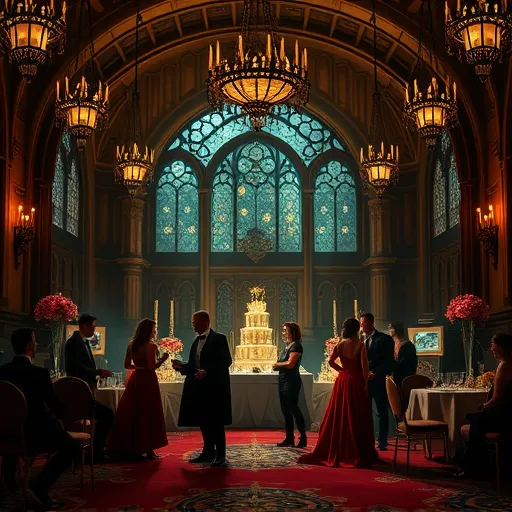

In [14]:
from gradio_client import Client
from IPython.display import Image, display

# Direct public Space check, independent of the Groq agent.
space = Client("https://black-forest-labs-flux-1-schnell.hf.space",
               verbose=False, httpx_kwargs={"timeout": 10})
job = space.submit(
    prompt="A luxurious superhero-themed masquerade gala in a fictional Gothic manor ballroom, original costumes, elegant Art Deco lighting",
    width=512, height=512, api_name="/infer",
)
try:
    image_path, seed = job.result(timeout=45)
except TimeoutError:
    job.cancel()
    raise
print("FLUX.1-schnell public Space seed:", seed)
from PIL import Image as PILImage
with PILImage.open(image_path) as generated:
    display(generated.convert("RGB"))
